

# **CSMODEL S15: GROUP 5 PHASE 2**
CELEMEN, MARK EDRIAN D.<br>
ENCALLADO, EDLYNN REI C.<br>
GILDORE, ANDREI MIGUEL C.<br>
LEE, HANNAH<br>
VILLORENTE, KHYLE RAEKA B.<br>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
!pip install category_encoders
from category_encoders import TargetEncoder, OneHotEncoder
import seaborn as sns

In [2]:
student_df = pd.read_csv('StudentPerformanceFactors.csv')

student_df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

After uploading, you can confirm the file is available using the code below:

# **Data Cleaning**
 We performed the following Data Cleaning techniquese: checked for null-values, multiple representations in categorical columns, and outlier values in numerical columns.

In [4]:
student_df.info()
student_df.shape

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

(6607, 20)

The data type of each variables above seem to be correct

The group started checking if the dataset has any nulls or empty values

In [5]:
student_df.isnull().any()

Hours_Studied                 False
Attendance                    False
Parental_Involvement          False
Access_to_Resources           False
Extracurricular_Activities    False
Sleep_Hours                   False
Previous_Scores               False
Motivation_Level              False
Internet_Access               False
Tutoring_Sessions             False
Family_Income                 False
Teacher_Quality                True
School_Type                   False
Peer_Influence                False
Physical_Activity             False
Learning_Disabilities         False
Parental_Education_Level       True
Distance_from_Home             True
Gender                        False
Exam_Score                    False
dtype: bool

There are null values represented in three columns. Let us list them and print the number of null values in each column

In [6]:
nan_variables = student_df.columns[student_df.isnull().any()].tolist()
print(nan_variables)

['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']


In [7]:
student_df[nan_variables].isnull().sum()

Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Since it is possible for Parental_Education_Level to be none (meaning there is no educational attainment), we can replace the null value with a sentinel value instead. Then we check if there are still null values left

In [8]:
student_df['Parental_Education_Level'] = student_df['Parental_Education_Level'].fillna('None')

student_df['Parental_Education_Level'].isnull().any()

np.False_

In [9]:
var_to_drop = list(['Teacher_Quality', 'Distance_from_Home'])
student_df = student_df.dropna(subset=var_to_drop)

student_df.isnull().any()


Hours_Studied                 False
Attendance                    False
Parental_Involvement          False
Access_to_Resources           False
Extracurricular_Activities    False
Sleep_Hours                   False
Previous_Scores               False
Motivation_Level              False
Internet_Access               False
Tutoring_Sessions             False
Family_Income                 False
Teacher_Quality               False
School_Type                   False
Peer_Influence                False
Physical_Activity             False
Learning_Disabilities         False
Parental_Education_Level      False
Distance_from_Home            False
Gender                        False
Exam_Score                    False
dtype: bool

Then we check for multiple representations for categorical columns

In [10]:
student_df['Parental_Involvement'].unique()

<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

The Parental_Involvement categorical values are all consistent

In [11]:
student_df['Access_to_Resources'].unique()

<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

The Access_to_Resources categorical values are all consistent

In [12]:
student_df['Extracurricular_Activities'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

The Extracurricular_Activities categorical values are all consistent

In [13]:
student_df['Motivation_Level'].unique()

<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

The Motivational_Level categorical values are all consistent

In [14]:
student_df['Internet_Access'].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

The Internet_Access categorical values are all consistent

In [15]:
student_df['Family_Income'].unique()

<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

The Family_Income categorical values are all consistent

In [16]:
student_df['Teacher_Quality'].unique()

<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

The Teacher_Quality categorical values are all consistent

In [17]:
student_df['School_Type'].unique()

<StringArray>
['Public', 'Private']
Length: 2, dtype: str

The School_Type categorical values are all consistent

In [18]:
student_df['Peer_Influence'].unique()

<StringArray>
['Positive', 'Negative', 'Neutral']
Length: 3, dtype: str

The Peer_Influence categorical values are all consistent

In [19]:
student_df['Learning_Disabilities'].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

The Learning_Disabilities categorical values are all consistent

In [20]:
student_df['Parental_Education_Level'].unique()

<StringArray>
['High School', 'College', 'Postgraduate', 'None']
Length: 4, dtype: str

The Parental_Education_Level has null values but categorical values are all consistent



In [21]:
student_df['Distance_from_Home'].unique()

<StringArray>
['Near', 'Moderate', 'Far']
Length: 3, dtype: str

The Distance_from_Home has categorical values are all consistent

In [22]:
student_df['Gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

The Gender categorical values are all consistent

There exists an exam score greater than 100 (101). We will check the row then to keep the data normalized, we will cap the score to 100

In [23]:
greater_than_100 = student_df['Exam_Score'] > 100
student_df[greater_than_100]

student_df.loc[student_df['Exam_Score'] > 100, 'Exam_Score'] = 100

# **I. Data Modelling**

For our data modelling, we used Lasso Regression to find out which features have significant coefficients to find the ones that seem to be the most relevant to our study. Since our study aims to discover which factors may have a significant effect on the exam scores of the students, Lasso Regression will be used to evaluate all columns of our dataset and will show the top significant coefficients.

In [24]:
#Declare the dependent category
Dependent = 'Exam_Score'

#Separate the columns by natures:
#Binary_col : columns with 2 options
Binary_Col = ['Gender', 'Internet_Access', 'School_Type', 'Learning_Disabilities', 'Extracurricular_Activities']
#Categorical_col : columns with more than 2 options
Categorical_Col = ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality', 'Peer_Influence', 'Parental_Education_Level', 'Distance_from_Home']
#Num_col : columns that are numerical in nature
Num_Col = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']

y = student_df[Dependent]
# Ensure 'Hours_Bin' is dropped if it exists from previous runs
if 'Hours_Bin' in student_df.columns:
    x = student_df.drop([Dependent, 'Hours_Bin'], axis=1)
else:
    x = student_df.drop(Dependent, axis=1)

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

onehot_encoder = OneHotEncoder(cols=Binary_Col, use_cat_names=True, handle_unknown='ignore')
target_encoder = TargetEncoder(cols=Categorical_Col)
scaler = StandardScaler()

# Encode binary_col features
x_train_temp = onehot_encoder.fit_transform(x_train)
x_test_temp = onehot_encoder.transform(x_test)

# Encode categorical_col features using target encoder
# The output of target_encoder should be used for the final dataframe
x_train_final = target_encoder.fit_transform(x_train_temp, y_train)
x_test_final = target_encoder.transform(x_test_temp)

# Scale numerical columns after all encoding is done
x_train_final[Num_Col] = scaler.fit_transform(x_train_final[Num_Col])
x_test_final[Num_Col] = scaler.transform(x_test_final[Num_Col])

# Align columns to ensure consistent features between train and test sets
x_train_final, x_test_final = x_train_final.align(x_test_final, join='left', axis=1, fill_value=0)

print(f'Original features: {x.shape[1]}')
print(f'Features after encoding: {x_train_final.shape[1]}')
print(f'Sample of final features: {x_train_final.columns.tolist()[:8]}')

Original features: 19
Features after encoding: 24
Sample of final features: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities_No', 'Extracurricular_Activities_Yes', 'Sleep_Hours', 'Previous_Scores']


Originally, the dataset contained 19 features, many of which were categorical. After encoding these categorical variables, the total number of model-ready features increased to 24.


In [25]:
# LassoCV to select alpha (5-fold)
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(x_train_final, y_train)
best_alpha = lasso_cv.alpha_
print('Selected alpha:', best_alpha)

# Fit final Lasso with best alpha
model = Lasso(alpha=best_alpha, random_state=42, max_iter=10000)
model.fit(x_train_final, y_train)

# Predictions
y_pred_test = model.predict(x_test_final)
y_pred_train = model.predict(x_train_final)

# Metrics
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_test = mean_absolute_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

print(f"\nLasso Regression Test RMSE (alpha={best_alpha}): {rmse_test:.4f} points")
print(f"Lasso Regression Test MAE (alpha={best_alpha}): {mae_test:.4f}")
print(f"Lasso Regression Test R2 (alpha={best_alpha}): {r2_test:.4f}")

print(f"Lasso Regression Train RMSE (alpha={best_alpha:}): {rmse_train:.4f} points")
print(f"Lasso Regression Train R2 (alpha={best_alpha}): {r2_train:.4f}")

coefficients = pd.Series(model.coef_, index=x_train_final.columns)
significant_coeffs = coefficients[coefficients.abs() > 0.01].sort_values(ascending=False)
zero_coeffs = len(coefficients[coefficients.abs() <= 0.01])

print("\nTop Significant Coefficients")
print(significant_coeffs.round(2))
print(f"\nNumber of features reduced (coefficients set to near-zero): {zero_coeffs} out of {x_train_final.shape[1]}")

Selected alpha: 0.00280029531179483

Lasso Regression Test RMSE (alpha=0.00280029531179483): 2.0338 points
Lasso Regression Test MAE (alpha=0.00280029531179483): 0.5089
Lasso Regression Test R2 (alpha=0.00280029531179483): 0.7216
Lasso Regression Train RMSE (alpha=0.00280029531179483): 2.0668 points
Lasso Regression Train R2 (alpha=0.00280029531179483): 0.7229

Top Significant Coefficients
Attendance                       2.30
Hours_Studied                    1.78
Teacher_Quality                  1.26
Parental_Involvement             1.15
Access_to_Resources              1.08
Motivation_Level                 1.02
Family_Income                    1.00
Peer_Influence                   0.99
Parental_Education_Level         0.97
Internet_Access_Yes              0.83
Learning_Disabilities_No         0.82
Distance_from_Home               0.81
Previous_Scores                  0.72
Tutoring_Sessions                0.60
Physical_Activity                0.18
Sleep_Hours                     -0.01

A Lasso model is generated with a selected alpha using 5-Fold Cross-Validation. This was done in order to avoid overfitting the model and yield for the lowest error in our model.

With exam scores ranging from 0–100, an RMSE of 2.0668 means the model’s predictions differ from the true score by about ±2 points on average, which indicates reasonably good predictive performance.

The MAE of about 0.51 points  also indicate that the absolute error on average of the model is quite small. Additionally, the R2 value of 72% also indicates that the predictors in the model mostly explain the variations behind the exam scores of students.

Finally, the difference between the Test v Train metrics are quite close, indicating that the model does not overfit and performs consistently well.


Only 6 of the 24 encoded features were shrunk to near zero, so most features kept a non-zero coefficient. The two largest positive coefficients were:

- Attendance (2.30)
- Hours Studied (1.78)

The largest negative coefficient was Non-Participation in Extracurricular Activities (-0.56). This means students who do not take part in extracurricular activities tend to have lower predicted scores. That is an association; it does not show that joining an activity would raise a score.

**Note on comparing coefficients:** the numeric columns were standardized, but the categorical columns were target-encoded, so the two groups of coefficients are not on the same scale. This can inflate categorical features such as Teacher_Quality (1.26). The check below re-fits the model with every feature standardized and categories coded in their natural order.

In [26]:
# Robustness check: put every feature on the same scale before comparing coefficients.
# Categories are coded in their natural order (Low < Medium < High, etc.).
# Fit on the full cleaned data; this is only for comparing coefficient sizes, not for reporting model accuracy.
ordinal = {'Low': 0, 'Medium': 1, 'High': 2}
check_df = student_df.drop(columns=['Hours_Bin'], errors='ignore').copy()

for col in ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality']:
    check_df[col] = check_df[col].map(ordinal)
check_df['Peer_Influence'] = check_df['Peer_Influence'].map({'Negative': 0, 'Neutral': 1, 'Positive': 2})
check_df['Parental_Education_Level'] = check_df['Parental_Education_Level'].map(
    {'None': 0, 'High School': 1, 'College': 2, 'Postgraduate': 3})
check_df['Distance_from_Home'] = check_df['Distance_from_Home'].map({'Near': 0, 'Moderate': 1, 'Far': 2})
for col, positive in {'Gender': 'Male', 'Internet_Access': 'Yes', 'School_Type': 'Private',
                      'Learning_Disabilities': 'Yes', 'Extracurricular_Activities': 'Yes'}.items():
    check_df[col] = (check_df[col] == positive).astype(int)

X_check = check_df.drop(columns='Exam_Score')
X_check_scaled = pd.DataFrame(StandardScaler().fit_transform(X_check), columns=X_check.columns)
lasso_check = LassoCV(cv=5, random_state=42, max_iter=10000).fit(X_check_scaled, check_df['Exam_Score'])

check_coeffs = pd.Series(lasso_check.coef_, index=X_check.columns).sort_values(key=abs, ascending=False)
print("Coefficients with all features standardized (points of exam score per 1 SD):")
print(check_coeffs.round(2).head(8))

Coefficients with all features standardized (points of exam score per 1 SD):
Attendance              2.29
Hours_Studied           1.76
Access_to_Resources     0.71
Previous_Scores         0.70
Parental_Involvement    0.69
Tutoring_Sessions       0.61
Family_Income           0.39
Peer_Influence          0.38
dtype: float64


With every feature on the same scale, Attendance and Hours Studied are still the two largest coefficients. Previous_Scores, Access_to_Resources, Parental_Involvement and Tutoring_Sessions come next, and Teacher_Quality is no longer near the top. This is why we treat the Teacher_Quality coefficient above (1.26) with caution.

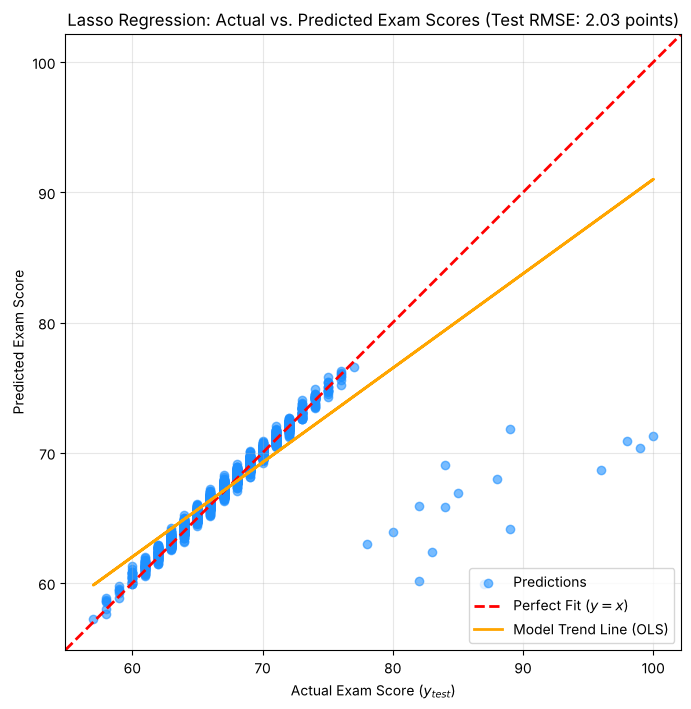

In [27]:

rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

min_value = np.min([y_test.min(), y_pred_test.min()])
max_value = np.max([y_test.max(), y_pred_test.max()])

range_value = (max_value - min_value) * 0.05
plot_min = min_value - range_value
plot_max = max_value + range_value

plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_test, alpha=0.6, color='dodgerblue', label='Predictions')

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color='red',
    linestyle='--',
    linewidth=2,
    label='Perfect Fit ($y=x$)'
)

z = np.polyfit(y_test, y_pred_test, 1)
p = np.poly1d(z)
plt.plot(
    y_test,
    p(y_test),
    color='orange',
    linestyle='-',
    linewidth=2,
    label='Model Trend Line (OLS)'
)

plt.title(f'Lasso Regression: Actual vs. Predicted Exam Scores (Test RMSE: {rmse:.2f} points)')
plt.xlabel('Actual Exam Score ($y_{test}$)')
plt.ylabel('Predicted Exam Score')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.gca().set_aspect('equal', adjustable='box')
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)

plt.show()

The scatter plot comparing actual to predicted exam scores visually proves the model's overall predictive capability. The graph's data points within the approximate range of 63-72 are generally clustering around the red 'perfect fit' line, indicating a strong positive correlation.

The graph also reinforces the quantitative metrics of the R2 score of approximately 0.72 and an RMSE of about 2.03 points, which suggest a robust model performance. The orange line, representing the model's trend, closely follows the ideal, signifying that for the majority of the data, predictions are quite accurate.

However, a key observation is the model's tendency towards 'regression to the mean,' where it appears to underestimate higher actual scores and overestimate lower actual scores, compressing predictions within a narrower range.

This behavior is largely attributed to the Lasso Regression's inherent feature selection process; by prioritizing a limited set of highly influential variables (like 'Attendance' and 'Hours_Studied') and regularizing others to near-zero, the model sacrifices some capacity to predict extreme outcomes. While this regularization enhances generalizability and prevents overfitting, it moderates the model's ability to capture the full spectrum of variance, particularly at the tails of the score distribution.

To further validate the quality of the linear regression model, we will also be analyzing the residuals.

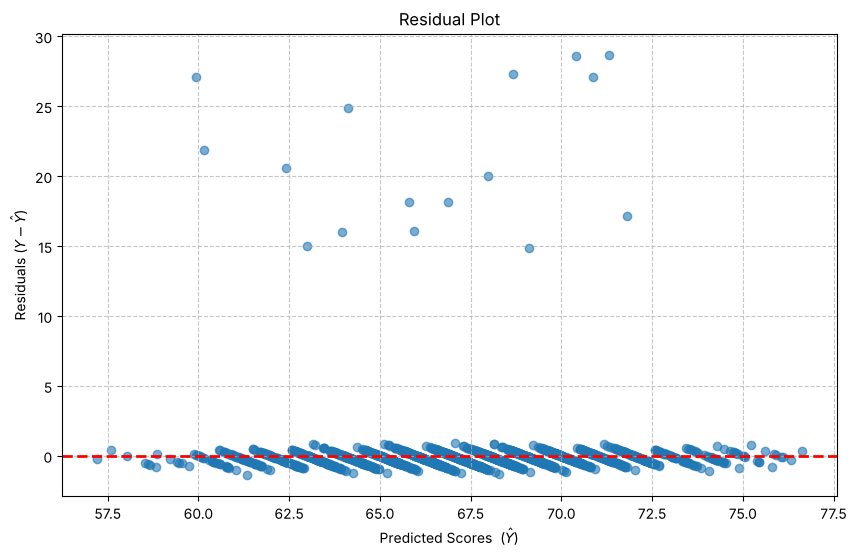

In [28]:
residuals = y_test - y_pred_test
plt.figure(figsize=(10, 6))
plt.scatter(x=y_pred_test, y=residuals, alpha=0.6)

plt.axhline(y=0, color='r', linestyle='--', linewidth = 2)
plt.title('Residual Plot')
plt.xlabel('Predicted Scores  ($\\hat{Y}$)')
plt.ylabel('Residuals ($Y - \\hat{Y}$)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Based on the residual plot, we infer that the model showed that most of the data points are clustered around the zero line which is a positive indicator that the model's predicitons are generally unbiased.

However, higher predicted scores show a noticable pattern where the spread of residuals widen which suggests that there is a higher variance or less consistent predicitons for students who are expected to have higher exam scores.

# **II. Statistical Inference**

In this section, we tested statistically whether our study-behavior variables really affect academic performance. Yes, the regression already suggested that Hours Studied and Attendance mattered, but we still needed stronger statistical evidence.

Before doing any correlation or ANOVA, we checked whether the variables follow a normal distribution. This matters because it tells us whether to use Pearson or Spearman, and whether ANOVA assumptions are acceptable.



```
# This is formatted as code
```

# Correlation Significance Test: Hours Studied vs Exam Score

Since our dataset has more than 5000 observations, Shapiro Wilk becomes overly sensitive. So instead of running it on all rows, we directly sampled 500 observations for Hours Studied and Exam Score, enough to detect skew without over-triggering the sensitivity.

In [29]:
from scipy.stats import shapiro, spearmanr

hours = student_df['Hours_Studied']
scores = student_df['Exam_Score']

# Sample of 500 for normality check
sh_hours = shapiro(hours.sample(n=500, random_state=42))
sh_scores = shapiro(scores.sample(n=500, random_state=42))

print("Shapiro Wilk:")
print(f"Hours Studied p value: {sh_hours.pvalue:.3e}")
print(f"Exam Score p value: {sh_scores.pvalue:.3e}")

Shapiro Wilk:
Hours Studied p value: 3.051e-01
Exam Score p value: 3.545e-16


Exam Score is clearly not normally distributed (p is far below 0.05). Hours Studied did not reject normality in this 500-row sample. Because at least one variable is non-normal, we used **Spearman correlation**, which works on ranks and does not require normality, to test whether study hours are related to exam scores.

### Hypotheses
* H₀: There is no significant relationship between Hours Studied and Exam Score.
* H₁: There is a significant relationship between Hours Studied and Exam Score.

In [30]:
# Spearman bc atleast one variable is non normal
corr_stat, corr_p = spearmanr(hours, scores)

print("\nUsing Spearman Correlation:")
print(f"Correlation coefficient: {corr_stat:.6f}")
print(f"p value: {corr_p:.3e}")


Using Spearman Correlation:
Correlation coefficient: 0.482885
p value: 0.000e+00


The Spearman correlation coefficient is 0.483, which sits in that “gray area” of being moderate but meaningful. We should also note the p value of 0.000. Since it is far below 0.05, we reject the null hypothesis.

Therefore, **Hours Studied is significantly related to Exam Score**. This means that the students who study more hours tend to score higher, and the effect is statistically significant, which also matches the model.

# ANOVA: Access to Educational Resources vs Exam Score

## Hypotheses
* H₀: All resource groups have the same mean exam score.
* H₁: At least one group has a different mean exam score.

Because Access_to_Resources has three groups (Low, Medium, High), we needed to see if their exam scores differ significantly.

Again using samples of 500:

In [31]:
from scipy.stats import f_oneway, kruskal

# Group data
low = student_df[student_df['Access_to_Resources'] == 'Low']['Exam_Score']
med = student_df[student_df['Access_to_Resources'] == 'Medium']['Exam_Score']
high = student_df[student_df['Access_to_Resources'] == 'High']['Exam_Score']

# Normality test for each group
print("Shapiro Wilk Normality Test:")
for group_name, group_data in zip(['Low', 'Medium', 'High'], [low, med, high]):
    stat, p = shapiro(group_data.sample(n=500, random_state=42))
    print(f"{group_name} p value: {p}")


Shapiro Wilk Normality Test:
Low p value: 2.7577463576001476e-19
Medium p value: 2.2359414918851094e-13
High p value: 7.219660811831252e-21


* Low: 2.76 × 10⁻¹⁹
* Medium: 2.24 × 10⁻¹³
* High: 7.22 × 10⁻²¹

All groups are < 0.05 hence, they are non-normal. However, normality is not strictly required for ANOVA if variances are similar.

In [32]:
# Variance check
print("\nGroup Standard Deviations:")
print(low.std(), med.std(), high.std())


Group Standard Deviations:
3.5619702967954296 3.884819547725734 3.974620297040195


Standard deviations:
* Low: 3.56
* Medium: 3.88
* High: 3.97

Since the variances are close, a one-way ANOVA is justifiable.

In [33]:
from scipy.stats import f_oneway

stat, p_value = f_oneway(low, med, high)

print("ANOVA Results:")
print(f"F statistic: {stat:.4f}")
print(f"p value: {p_value:.3e}")

ANOVA Results:
F statistic: 94.1199
p value: 5.109e-41


In [34]:
# Average exam score per resource group, so the size of the gap is visible next to the p-value
student_df.groupby('Access_to_Resources')['Exam_Score'].agg(['count', 'mean']).round(2).loc[['Low', 'Medium', 'High']]

,count,mean
Access_to_Resources,,
Low,1287,66.23
Medium,3251,67.15
High,1926,68.11


* F statistic: 94.12
* p value: 5.11 × 10⁻⁴¹

Because the p value is extremely small with it being < 0.05, we reject the null hypothesis. This means that **Exam Scores significantly differ based on Access to Resources**.

## Chi Square Test of Independence

Now we check whether study hours and resource access are associated or independent. It tests whether study behaviors cluster together, meaning, do students who study more also tend to have more resources?

In [35]:
from scipy.stats import chi2_contingency

student_df['Hours_Bin'] = pd.cut(student_df['Hours_Studied'],
                                 bins=[-1,5,10,15,20,25,30,40,100],
                                 labels=['0-5','6-10','11-15','16-20','21-25','26-30','31-40','41+'])

contingency = pd.crosstab(student_df['Hours_Bin'], student_df['Access_to_Resources'])
display(contingency)

chi2, p, dof, expected = chi2_contingency(contingency)
print("\nChi square Test of Independence:")
print(f"Chi square statistic: {chi2:.4f}")
print(f"p value: {p:.3e}")

Access_to_Resources,High,Low,Medium
Hours_Bin,,,
0-5,19,14,24
6-10,89,56,152
11-15,338,196,578
16-20,578,399,1022
21-25,545,398,908
26-30,278,179,442
31-40,79,44,124
41+,0,1,1



Chi square Test of Independence:
Chi square statistic: 12.3650
p value: 5.770e-01


* p = 0.5770

Since this is > 0.05, we fail to reject the null hypothesis.
Surprisingly, **access to resources does not predict whether a student studies more hours**.

Students’ study habits seem independent of their level of resource access. This gives us a new insight in which academic advantages do not necessarily translate to more time spent studying.

## ANOVA across Study Hour Bins

Now we bin the hours studied and check whether exam scores differ across the bins. This test only shows whether the groups differ. It does not show where, if anywhere, extra study hours stop helping.

In [36]:
from scipy.stats import f_oneway

groups = [student_df[student_df['Hours_Bin'] == b]['Exam_Score']
          for b in student_df['Hours_Bin'].cat.categories]

group_names = list(student_df['Hours_Bin'].cat.categories)

groups_nonempty = [g for g in groups if len(g) > 0]
names_nonempty = [name for name, g in zip(group_names, groups) if len(g) > 0]

anova_stat_bins, anova_p_bins = f_oneway(*groups_nonempty)
print("ANOVA across Hours_Bin:")
print(f"F-statistic: {anova_stat_bins:.4f}, p-value: {anova_p_bins:.3e}")

ANOVA across Hours_Bin:
F-statistic: 216.2109, p-value: 1.570e-289


* p value = 1.57 × 10⁻²⁸⁹

With the p being insanely small, we reject the null hypothesis. **There are statistically significant differences in exam scores across different study-hour ranges**.

This test confirms the earlier correlation but more in a categorical, more “practical” manner. It shows that the differences in scores between study-hour groups are unlikely to be random.

# Correlation Significance Test: Attendance vs Exam Score

Similar to our analysis of study hours, we now examine the relationship between Attendance and Exam Score. The Lasso Regression model indicated that Attendance had the highest positive coefficient (2.30), suggesting it is a strong predictor. We will now verify this statistically.

First, we check the normality of the Attendance data to determine the appropriate correlation test (Pearson vs. Spearman).

In [37]:
from scipy.stats import shapiro, spearmanr

attendance = student_df['Attendance']
scores = student_df['Exam_Score']

# Shapiro-Wilk test for normality (using a sample of 500 to avoid over-sensitivity)
sh_att = shapiro(attendance.sample(n=500, random_state=42))
sh_scores = shapiro(scores.sample(n=500, random_state=42))

print("Shapiro-Wilk Normality Test Results:")
print(f"Attendance p-value: {sh_att.pvalue:.3e}")
print(f"Exam Score p-value:  {sh_scores.pvalue:.3e}")

Shapiro-Wilk Normality Test Results:
Attendance p-value: 1.337e-11
Exam Score p-value:  3.545e-16


**Normality Check Interpretation:**

If the p-values are less than 0.05, we reject the null hypothesis that the data is normally distributed.

*   **Attendance** is often negatively skewed (students tend to have high attendance), so we expect a low p-value.
*   **Exam Score** was previously found to be non-normal.

Since the data is likely not normally distributed, we will use the Spearman Rank Correlation, which assesses the monotonic relationship between the variables rather than a strictly linear one.



## Hypotheses
* H₀: There is **no significant relationship** between Attendance and Exam Score.
* H₁: There is a **significant relationship** between Attendance and Exam Score.



Spearman Correlation Results (Attendance vs. Exam Score):
Correlation coefficient: 0.672794
p-value: 0.000e+00


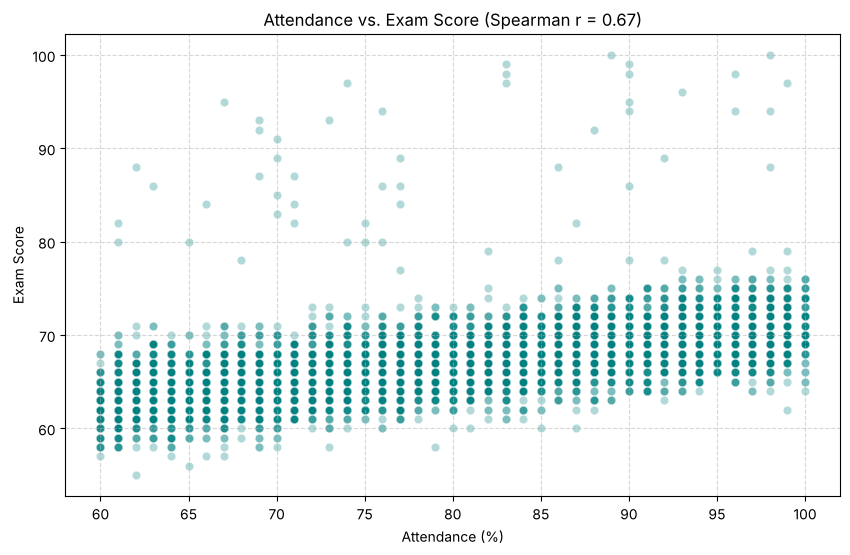

In [38]:
# Spearman Correlation Test
corr_stat_att, corr_p_att = spearmanr(attendance, scores)

print("\nSpearman Correlation Results (Attendance vs. Exam Score):")
print(f"Correlation coefficient: {corr_stat_att:.6f}")
print(f"p-value: {corr_p_att:.3e}")

# Visualization of the relationship
plt.figure(figsize=(10, 6))
sns.scatterplot(x=attendance, y=scores, alpha=0.3, color='teal')
plt.title(f'Attendance vs. Exam Score (Spearman r = {corr_stat_att:.2f})')
plt.xlabel('Attendance (%)')
plt.ylabel('Exam Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

1.   **P-value:** The p-value is far below 0.05, so we reject the null hypothesis. The relationship between Attendance and Exam Score is statistically significant, not just due to random chance.

2.   **Coefficient:**

*   The Spearman coefficient is about 0.67, a strong positive relationship.
*   This matches the Lasso result, where Attendance had the highest coefficient (2.30).
*   Students with higher attendance rates tend to have higher exam scores.

This reinforces the Lasso model's finding that attendance is the factor most strongly associated with exam scores. It does not show that attending more causes higher scores.

# Correlation Significance Test: Teacher Quality vs Exam Score

In [39]:
from scipy.stats import shapiro, spearmanr

teacher_quality = student_df['Teacher_Quality']
scores = student_df['Exam_Score']

# Teacher quality is ordinal, so code it in its natural order: Low < Medium < High
teacher_quality_mapping = {'Low': 0, 'Medium': 1, 'High': 2}
teacher_quality_encoded = teacher_quality.map(teacher_quality_mapping)

# Teacher quality only has 3 ordered levels, so a normality test on it is not informative.
# We only check Exam Score.
sh_scores = shapiro(scores.sample(n=500, random_state=42))
print("Shapiro Wilk:")
print(f"Exam Score p value: {sh_scores.pvalue:.3e}")

Shapiro Wilk:
Exam Score p value: 3.545e-16


Exam Score is not normally distributed, and Teacher Quality is an ordinal variable with three levels (Low < Medium < High). Hence, we used **Spearman correlation**, which works on ranks, to test whether teacher quality is related to exam scores.

### Hypotheses
* H₀: There is no significant relationship between Teacher Quality and Exam Score.
* H₁: There is a significant relationship between Teacher Quality and Exam Score.

In [40]:
# Spearman because Exam Score is non-normal and Teacher Quality is ordinal.
# Use the encoded column (Low=0, Medium=1, High=2), not the raw text labels.
corr_stat, corr_p = spearmanr(teacher_quality_encoded, scores)

print("\nUsing Spearman Correlation:")
print(f"Correlation coefficient: {corr_stat:.6f}")
print(f"p value: {corr_p:.3e}")

if corr_p < 0.05:
    print("\nInterpretation: Statistically significant correlation.")
else:
    print("\nInterpretation: No statistically significant relationship.")


Using Spearman Correlation:
Correlation coefficient: 0.081097
p value: 6.594e-11

Interpretation: Statistically significant correlation.


The Spearman correlation coefficient is about 0.08, a **weak positive** correlation. The p value is far below 0.05, so we reject the null hypothesis: Teacher Quality is statistically related to Exam Score, but the relationship is weak.

The positive direction agrees with the Lasso model's positive coefficient for Teacher_Quality, so there is no contradiction between the two results.

**Correction:** an earlier version of this notebook reported a coefficient of -0.055 and described it as a "paradox" with the Lasso result. That value came from passing the raw text labels to `spearmanr` instead of the encoded column, which ranks the labels alphabetically (High, Low, Medium) rather than in their real order. The code above now uses the correct order.

# **III. Insights and Conclusions**


Our statistical inference aimed to validate the findings from the Lasso Regression model and look at further relationships within the dataset. All of the results below are associations. This dataset cannot show that any factor causes higher or lower scores.

**Hours Studied and Exam Score** had a positive Spearman correlation of `0.483` with an extremely low p-value. Students who study more hours tend to score higher.

**Attendance and Exam Score** had a positive Spearman correlation of `0.673` with an extremely low p-value. Students with higher attendance tend to score higher. This agrees with the Lasso model, where Attendance had the highest coefficient.

An ANOVA on **Access to Educational Resources and Exam Score** found statistically significant differences in exam scores across resource levels (F-statistic `94.12`, p-value `5.109e-41`). The gap is small: average scores were about 66.2 (Low), 67.1 (Medium) and 68.1 (High), roughly 1.9 points between Low and High. This is consistent with the Lasso model's positive coefficient for 'Access_to_Resources'.

The Chi-square Test of Independence between **Study Hour Bins and Access to Resources** gave a p-value of `0.577`, so we found no statistically significant association between study hours and resource access. Some study-hour bins have very few students (the 41+ bin has 2), so this result is less reliable for the extreme bins. Not finding an association is not proof that the two are unrelated.

An **ANOVA across Study Hour Bins** gave an F-statistic of `216.21` and a p-value of `1.570e-289`. Exam scores differ significantly between study-hour groups, which fits the positive correlation above. This test does not tell us where, if anywhere, extra study hours stop helping.

Finally, **Teacher Quality vs Exam Score** showed a statistically significant but weak positive correlation of `0.081` (p-value `6.594e-11`). Its direction agrees with the Lasso model's positive coefficient, but the relationship is weak, and Teacher_Quality drops out of the top coefficients once all features are put on the same scale. Teacher Quality, as measured in this dataset, appears to have a small relationship with exam scores compared with Attendance and Hours Studied.
